# Cross-correlation

This notebook creates Figs. 6 and 7. of the manuscript.

We start by creating and storing videos.   
Then we compute ffts and save the results.
Finally, we compute correlation function for a particular wave vector and display the results.

## Configuration

In [ ]:
# all experimental setup is in ep_video.py
from epvid import *

correlation_settings = {
    "tmax": 800,  # Maximum time index in the correlation, can be None - full data
    "kmin": 0,  # Minimum wavevector index in the correlation
    "kmax": 95,  # Maximum wavevector index in the correlation
    "phimin": -np.pi/20,  # Minimum angle in the correlation
    "phimax": np.pi/20,   # Maximum angle in the correlation
    "use_rfft2": True,  # Whether to use 2D real FFT for correlation
    "use_window": True,  # Whether to apply a window function before correlation
}

# if data needs to be recomputed, set RECOMPUTE to True
# You need more than 230 GB of free space for videos and for fft-s
RECOMPUTE = False
NRUNS = 64


In [29]:
from pathlib import Path
import tempfile

#data_dir = Path(tempfile.mkdtemp(prefix="cross_correlation_"))
data_dir = Path("data")
print(f"Temporary data directory: {data_dir}")

Temporary data directory: data


## Generate videos

In [30]:
if RECOMPUTE:
    print("Recomputing data")
    microscope_sim.compute_lut()
    for run in range(0,NRUNS):
        image_seq = triggered_video(seed = 0, use_sensor = False)
        save_video(data_dir / f"sequence_{run}", image_seq)
else:
    print("Using precomputed data")

Using precomputed data


## Compute correlation functions

### Build K-space mask

We define a fft mask for the fft data so that we reduce data storage requirenment.
We are only interested in wave vectors along the flow in the horizontal direction.
We use rfft2 so the mask is a half-space mask.

Analysis settings
----------------------------------------
Image shape:        (512, 512)
Max k-space index:  95
Min k-space index:  0
Length of k-space:  1413
Use window function: True


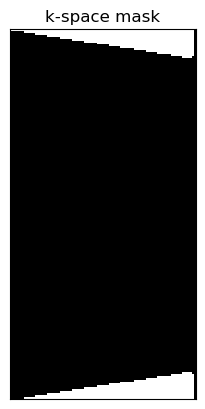

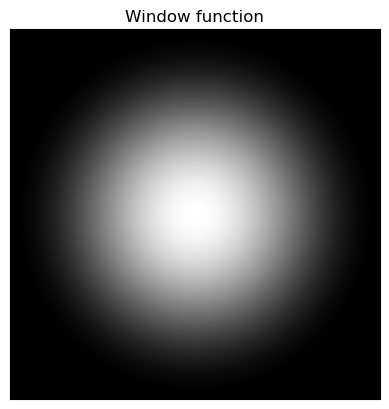

In [31]:
# Reciprocal space mask and window function setup

_kin = np.fft.fftfreq(sensor_shape[0],d = 1/sensor_shape[0])
_kjn = np.fft.fftfreq(sensor_shape[1],d = 1/sensor_shape[1])
_ki,_kj = np.meshgrid(_kin,_kjn, indexing = 'ij')
_k = np.sqrt((_ki)**2+(_kj)**2)
_phi = np.arctan2(_ki,_kj)

phimask = np.logical_and(_phi < correlation_settings["phimax"], _phi >= correlation_settings["phimin"])

#: reciprocal space mask array
kmask = np.logical_and(_k < correlation_settings["kmax"], _k >= correlation_settings["kmin"])
kmask = np.logical_and(kmask, phimask)

if correlation_settings["use_rfft2"]:
    kmask = kmask[:,:sensor_shape[1]//2+1].copy()

def print_kmask_info():
    print("Analysis settings")
    print("-" * 40)

    print(f"Image shape:        {sensor_shape}")
    print(f"Max k-space index:  {correlation_settings['kmax']}")
    print(f"Min k-space index:  {correlation_settings['kmin']}")
    print(f"Length of k-space:  {kmask.sum()}")
    print(f"Use window function: {correlation_settings['use_window']}")
   

print_kmask_info()

# buld kmask_crop for display purpose only
kmask_crop = np.zeros((correlation_settings["kmax"]*2+1,correlation_settings["kmax"]+1), kmask.dtype)
kmask_crop[0:correlation_settings["kmax"],:] = kmask[0:correlation_settings["kmax"], 0:correlation_settings["kmax"] + 1]
kmask_crop[-1:-correlation_settings["kmax"]:-1,:] = kmask[-1:-correlation_settings["kmax"]:-1,0:correlation_settings["kmax"] + 1]
plt.imshow(kmask_crop,cmap = "gray",interpolation = "nearest")
plt.xticks([])
plt.yticks([])
plt.title("k-space mask")

assert kmask.sum() == kmask_crop.sum()
plt.figure()

window = mp.blackman(sensor_shape) if correlation_settings["use_window"] else mp.ones(sensor_shape)
plt.imshow(window,cmap = "gray",interpolation = "nearest")
plt.xticks([])
plt.yticks([])
t = plt.title("Window function")

#plt.figure()
#plt.imshow(kmask)
#plt.figure()


### Compute the FFTs

In [32]:
import scipy.fft as spfft
fft2 = spfft.rfft2 if correlation_settings["use_rfft2"] else spfft.fft2

def fft_sequence(sequence, kmask = None, window = None, apply_sensor = True):
    
    for i, (im1,im2) in enumerate(sequence):
        if window is None:
            window = 1.

        if apply_sensor:
            im1 = sensor.capture(xp.array(im1)) if im1 is not None else None
            im2 = sensor.capture(xp.array(im2)) if im2 is not None else None

        window = xp.asarray(window)
        f1 = fft2(im1 * window) if im1 is not None else None
        f2 = fft2(im2 * window) if im2 is not None else None

        if kmask is not None:
            f1 = f1[kmask] if f1 is not None else None
            f2 = f2[kmask] if f2 is not None else None

        f1 = xp.array(f1) if f1 is not None else None
        f2 = xp.array(f2) if f2 is not None else None
        
        yield f1, f2

def save_fft(filename, seq):
    """Save a sequence of images to a file.
    This function first evaluates the sequence of images and then saves them to separate numpy files for the two video streams and their corresponding masks.
    """
    fft1 = []
    fft2 = []
    for i, frames in enumerate(seq):
        a, b = frames
        if a is not None:
            fft1.append(a)
        if b is not None:
            fft2.append(b)

    np.save(f"{filename}_fft1.npy", fft1)
    np.save(f"{filename}_fft2.npy", fft2)

if RECOMPUTE:
    print("Recomputing FFT sequences")
    for run in range(NRUNS):
        print_progress(run, NRUNS)
        image_seq = open_video(data_dir / f"sequence_{run}")
        fft_seq = fft_sequence(image_seq, window = window, kmask = kmask)
        save_fft(data_dir / f"sequence_{run}", fft_seq)
    print_progress(NRUNS, NRUNS)
else:
    print("Using precomputed FFT sequences")



Using precomputed FFT sequences


### Compute correlation functions

In [33]:
# Cross-correlation analysis of FFT sequences
from scipy.signal import correlate, convolve

# wave vector indices for selecting FFT components
ki,kj = -3,53

def cross_correlate(mask1, sig1, mask2, sig2):
    sig1 = sig1 * mask1
    sig2 = sig2 * mask2
    count = correlate(mask1, mask2, method = "fft", mode = "same")
    corr = correlate(sig1, sig2, method = "fft", mode = "same")
    sig_sum1 = correlate(sig1, mask2, method = "fft", mode = "same")
    sig_sum2 = correlate(mask1, sig2, method = "fft", mode = "same")
    sq_sum1 = correlate(np.abs(sig1)**2, mask2, method = "fft", mode = "same")
    sq_sum2 = correlate(mask1, np.abs(sig2)**2, method = "fft", mode = "same")

    corr = np.where(count != 0, corr / count, 0)
    sig_sum1 = np.where(count != 0, sig_sum1 / count, 0)
    sig_sum2 = np.where(count != 0, sig_sum2 / count, 0)
    sq_sum1 = np.where(count != 0, sq_sum1 / count, 0)
    sq_sum2 = np.where(count != 0, sq_sum2 / count, 0)

    sq_sum = 0.5 * (sq_sum1 + sq_sum2)

    return count, corr, sig_sum1, sig_sum2, sq_sum

def average(data, kernel_size = 96):
    kernel = np.asarray([1./kernel_size]*kernel_size)
    y = convolve(data,kernel, mode = "same", method = "fft")
    return y

def unmask(data, mask):
    out = np.zeros(mask.shape, data.dtype)
    out[np.bool(mask)] = data
    return out

def load_fft_data(fname, ki = ki, kj = kj):
    mask1 = np.load(f"{fname}_mask1.npy")
    mask2 = np.load(f"{fname}_mask2.npy")
    fft1 = np.load(f"{fname}_fft1.npy")
    fft2 = np.load(f"{fname}_fft2.npy")
    return (mask1, fft1), (mask2,  fft2)

def select_fft(data, ki = ki, kj = kj, kmask = kmask):
    if data is None:
        return 0. + 0j
    mask = np.zeros_like(kmask)
    data = np.asarray(data)
    mask[ki,kj] = 1
    mask = mask[kmask]
    return data[...,mask].sum(axis = -1)

def select_signal(data, ki = ki, kj = kj, kmask = kmask):
    mask, fft = data
    sig = unmask(select_fft(fft, ki = ki, kj = kj, kmask = kmask), mask)
    return sig

def analyze_data(fname, ki = ki, kj = kj, kmask = kmask):

    (mask1, fft1), (mask2, fft2) = load_fft_data(fname)

    sig1 = select_signal((mask1, fft1), ki = ki, kj = kj, kmask = kmask)
    sig2 = select_signal((mask2, fft2), ki = ki, kj = kj, kmask = kmask)

    base = np.conj(sig1.sum()/mask1.sum()) * sig2.sum()/mask2.sum()

    count, corr, sig1_sum, sig2_sum, sq_sum = cross_correlate(mask1, sig1, mask2, sig2)

    norm = np.where(count > 1, count/(count-1), 0)

    var_tau = norm * (sq_sum - 0.5*(np.abs(sig1_sum)**2 + np.abs(sig2_sum)**2))
    var = average(var_tau)
    var0 = np.fft.ifftshift(var)[0]

    error = var_tau/var0 - var/var0

    # baseline corrected correlation
    # baseline corrected correlation
    corr_b = (corr - base) / var0
    # compensated correlation
    corr_c = (norm*(corr - (sig1_sum * sig2_sum))) / var0
    # structured correlation
    corr_s = (corr_c - np.exp(1j*np.angle(corr_c)) * error )

    corr_w = corr_c.copy()

    for i in range(4):
        w = 2 * corr_w / (1+np.abs(corr_w)**2)
        corr_w = corr_c - error *  w

    return count, var0, (corr_b, corr_c, corr_s, corr_w)

corr_b = []
corr_c = []
corr_s = []
corr_w = []
corr_n = []
corr_v = []

print(f"Analyzing {NRUNS} runs")

for i in range(NRUNS):
    n, v, (b, c, s, w) = analyze_data(data_dir / f"sequence_{i}")
    corr_b.append(b)
    corr_c.append(c)
    corr_s.append(s)
    corr_w.append(w)
    corr_n.append(n)
    corr_v.append(v)

# Prepare correlation data for plotting

# time axis for correlation plots
corr_x = np.fft.fftshift(np.fft.fftfreq(len(c), d=1.0/len(c)))
# baseline normalized correlations
corr_b = np.array(corr_b)
# compensated correlations
corr_c = np.array(corr_c)
# structured correlations
corr_s = np.array(corr_s)
# weighted correlations
corr_w = np.array(corr_w)
# correlation counts
corr_n = np.array(corr_n)
# correlation variances
corr_v = np.array(corr_v)

np.save(data_dir / "corr_x.npy", corr_x)
np.save(data_dir / "corr_b.npy", corr_b)
np.save(data_dir / "corr_c.npy", corr_c)
np.save(data_dir / "corr_s.npy", corr_s)
np.save(data_dir / "corr_w.npy", corr_w)
np.save(data_dir / "corr_n.npy", corr_n)
np.save(data_dir / "corr_v.npy", corr_v)

Analyzing 64 runs


In [27]:
corr_x = np.load(data_dir / "corr_x.npy")
corr_b = np.load(data_dir / "corr_b.npy")
corr_c = np.load(data_dir / "corr_c.npy")
corr_s = np.load(data_dir / "corr_s.npy")
corr_w = np.load(data_dir / "corr_w.npy")
corr_n = np.load(data_dir / "corr_n.npy")
corr_v = np.load(data_dir / "corr_v.npy")

In [34]:
# shot noise estimation
print("Estimating SNR")

noise = np.asarray([fft2(sensor.capture(mp.ones(sensor.shape)) * window)[kmask] for _ in range(10000)])
noise = select_fft(noise, ki = ki, kj = kj, kmask = kmask) 
noise = np.var(noise.real, axis = 0) + np.var(noise.imag, axis = 0)

var = corr_v.mean()

scale = (var - noise)/ var

snr =  (var - noise) / noise

print(f"Scale: {scale}, SNR: {snr}")


Estimating SNR
Scale: 0.9922010039999092, SNR: 127.22163262916887


### Correlation - mean

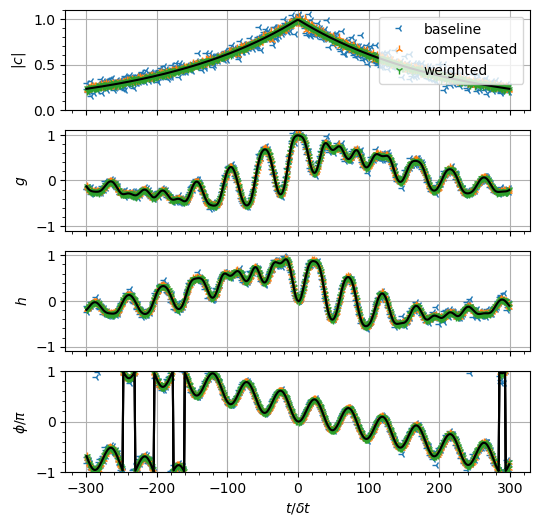

In [35]:
# Display measured correlation mean and compare with theory.

def model_func(t, ki = ki, kj = kj, scale = 1.):
    """Computes the model correlation function."""
    
    dkw = 2*np.pi/object_plane.width
    dkh = 2*np.pi/object_plane.height

    kx = dkw * kj
    ky = dkh * ki

    e = ep_sim.electric_field
    d = ep_sim.diffusion_coefficients.mean()
    k0 = microscope.light_source.wavenumber
    k = k0 * 1.33
    qz = np.sqrt(k**2 - (kx**2 + ky**2)) - k
    k2 = kx**2 + ky**2
    decay = d * (k2 + qz**2) * np.abs(t)

    phase = central_velocity  * t * kx

    omega = 2*np.pi * ep_sim.ac_frequency
    mu = ep_sim.get_complex_mobility(z = 0).mean()
    phi = np.angle(mu)
    mu = np.abs(mu)

    phase -= e * mu / omega * kx * (np.cos(omega * t + phi) - np.cos(phi))
    
    c = np.exp(-decay  - 1j*phase)
    return c * scale

TMAX = 300
YMAX = 1.1
YMIN = -1.1

LINESTYLE = ("3","2","1")
LABELS = ("baseline", "compensated", "weighted")

MODELSTYLE = "-k"
MODELSTYLE2 = ":k"

corrs = (corr_b, corr_c, corr_w)

fig,axs = plt.subplots(4,1, figsize =(6,6))

for i, corr in enumerate(corrs):
    c = corr.mean(axis=0)
    v = corr_v.mean(axis=0)

    xmask = np.logical_and(np.abs(corr_x) < TMAX, corr_x != 0)

    x,c = corr_x[xmask], c[...,xmask]
    t = x * ep_sim.time_step
    
    y = model_func(t,ki,kj,scale)

    axs[0].plot(x,np.abs(c) ,LINESTYLE[i], label = LABELS[i])
    axs[0].plot(x,np.abs(y),MODELSTYLE)
    #axs[0].plot(x,np.abs(y2)**2,MODELSTYLE2)
    axs[1].plot(x,c.real,LINESTYLE[i], label = LABELS[i])
    axs[1].plot(x,y.real,MODELSTYLE)
    
    axs[2].plot(x,c.imag,LINESTYLE[i], label = LABELS[i])
    axs[2].plot(x,y.imag,MODELSTYLE)
    axs[3].plot(x,np.angle(c)/np.pi,LINESTYLE[i], label = LABELS[i])
    axs[3].plot(x,np.angle(y)/np.pi,MODELSTYLE)


#axs[0].set_title(r"$c=g+ih=|c|e^{i\phi}$; $\boldsymbol{q}=\delta q"+f"({ki},{kj})"+"$")
axs[0].set_xticklabels([])
axs[1].set_xticklabels([])
axs[2].set_xticklabels([])
#axs[0].set_ylim(0,1e4)
axs[0].set_ylim(0,YMAX)
axs[1].set_ylim(YMIN,YMAX)
axs[2].set_ylim(YMIN,YMAX)
#axs[2].set_xlabel("t/p")
axs[3].set_ylim(-1,1)
axs[3].set_xlabel(r"$t/\delta t$")

axs[0].set_ylabel(r"$|c|$")
axs[1].set_ylabel(r"$g$")
axs[2].set_ylabel(r"$h$")
axs[3].set_ylabel(r"$\phi/\pi$")

axs[0].legend(loc="upper right")

for ax in axs:
    ax.grid()
    #ax.set_xlim(-TMAX/REGULAR_SAMPLING_INTERVAL,TMAX/REGULAR_SAMPLING_INTERVAL)    
    ax.minorticks_on()

plt.savefig("correlator.pdf")
plt.savefig("correlator.png")


### Correlation - std

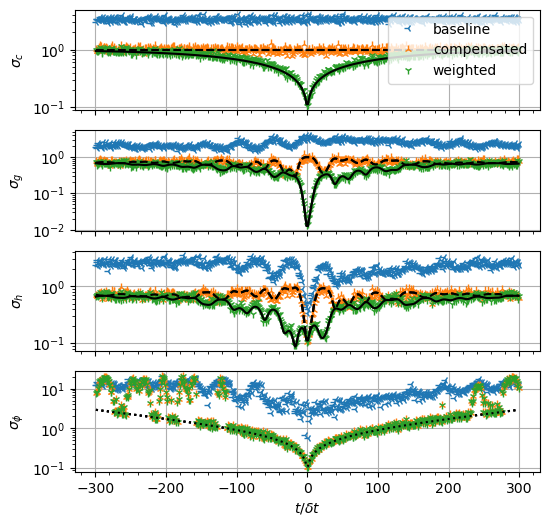

In [36]:
# Display measured correlation std and compare with theory

def model_std(m,w):
    """Computes the theoretical standard deviation of the model's real and imaginary parts."""
    g = m.real
    h = m.imag
    var_g = 0.5 * (1 - np.abs(m)**2) + g**2 - 2*w.real * g + 0.5 * w.real**2 *(1 + np.abs(m)**2)
    var_h = 0.5 * (1 - np.abs(m)**2) + h**2 - 2*w.imag * h + 0.5 * w.imag**2 *(1 + np.abs(m)**2)
    return np.sqrt(var_g) + 1j*np.sqrt(var_h)

MODELSTYLE = "-k"
MODELSTYLE2 = "--k"
MODELSTYLE3 = ":k"

fig,axs = plt.subplots(4,1, figsize =(6,6))

for i, corr in enumerate(corrs): 
    count = corr_n[i]
    phi = np.angle(corr)
    phi_std = np.std(phi, axis=0) * np.sqrt(count)  

    c = (corr.real.std(axis=0) + 1j*corr.imag.std(axis=0))* np.sqrt(count)

    xmask = np.logical_and(np.abs(corr_x) < TMAX, corr_x != 0)

    x,c = corr_x[xmask], c[...,xmask]
    phi_std = phi_std[...,xmask]
    count = count[...,xmask]

    t = x * ep_sim.time_step
    

    
    m = model_func(t,ki,kj,scale)
    g = m.real
    h = m.imag
    w = 2*m/(1+np.abs(m)**2)



    y = model_std(m,w)
    y2 = model_std(m,0)
    
    axs[0].semilogy(x,np.abs(c),LINESTYLE[i], label = LABELS[i])
    axs[0].plot(x,np.abs(y),MODELSTYLE)
    axs[0].plot(x,np.abs(y2),MODELSTYLE2)

    axs[1].semilogy(x,c.real,LINESTYLE[i], label = LABELS[i])
    axs[1].plot(x,y.real,MODELSTYLE)
    axs[1].plot(x,y2.real,MODELSTYLE2)
    
    axs[2].semilogy(x,c.imag,LINESTYLE[i], label = LABELS[i])
    axs[2].plot(x,y.imag,MODELSTYLE)
    axs[2].plot(x,y2.imag,MODELSTYLE2)

    axs[3].semilogy(x,phi_std,LINESTYLE[i], label = LABELS[i])
    axs[3].plot(x,[np.sqrt(0.5*(1 - np.abs(mi)**2)/np.abs(mi)**2) for mi in m],MODELSTYLE3)



axs[0].set_xticklabels([])
axs[1].set_xticklabels([])
axs[2].set_xticklabels([])
axs[3].set_xlabel(r"$t/\delta t$")

axs[0].set_ylabel(r"$\sigma_c$")
axs[1].set_ylabel(r"$\sigma_g$")
axs[2].set_ylabel(r"$\sigma_h$")
axs[3].set_ylabel(r"$\sigma_\phi$")

axs[0].legend(loc="upper right")

for ax in axs:
    ax.grid()
    ax.minorticks_on()

plt.savefig("noise.pdf")
plt.savefig("noise.png")

    


In [39]:
corr_b.shape

(64, 65536)

In [41]:
65536/800

81.92